In [14]:
import os
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image

from copy import deepcopy

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using device: cpu
PyTorch version: 2.11.0+cpu


In [15]:
CAT_IDX, DOG_IDX = 3, 5

train_transform = transforms.Compose([
    transforms.Resize(64),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

val_transform = transforms.Compose([
    transforms.Resize(64),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

In [16]:
class BinaryCIFAR(Dataset):
    """
    Оставляет только кошек и собак.
    Метки:
        0 — cat
        1 — dog
    """
    def __init__(self, dataset, transform=None):
        self.transform = transform
        self.images = []
        self.labels = []

        for img, label in dataset:
            if label == CAT_IDX:
                self.images.append(img)
                self.labels.append(0)
            elif label == DOG_IDX:
                self.images.append(img)
                self.labels.append(1)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]

        if self.transform is not None:
            img = self.transform(img)

        return img, label

In [17]:
train_full = datasets.CIFAR10(root="./data", train=True, download=True)
val_full = datasets.CIFAR10(root="./data", train=False, download=True)

train_dataset = BinaryCIFAR(train_full, transform=train_transform)
val_dataset = BinaryCIFAR(val_full, transform=val_transform)

print(f"Train size: {len(train_dataset)}")
print(f"Val size: {len(val_dataset)}")
print("Класс 0: кошка, Класс 1: собака")

100%|██████████| 170M/170M [27:55<00:00, 102kB/s] 


Train size: 10000
Val size: 2000
Класс 0: кошка, Класс 1: собака


In [18]:
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")

Train batches: 157
Val batches: 16


In [19]:
def denormalize(img):
    """
    Преобразует тензор [3, H, W] обратно в изображение для отображения.
    Используется нормализация (0.5, 0.5, 0.5).
    """
    img = img.permute(1, 2, 0).cpu().numpy()
    img = img * 0.5 + 0.5
    return np.clip(img, 0, 1)

# **Задание 1.1 Выведите 9 случайных изображений в сетке 3×3 с указанием классов (cat/dog). Визуально определите, какие признаки отличают кошку от собаки: форма ушей, морды, текстура шерсти, цвет.**

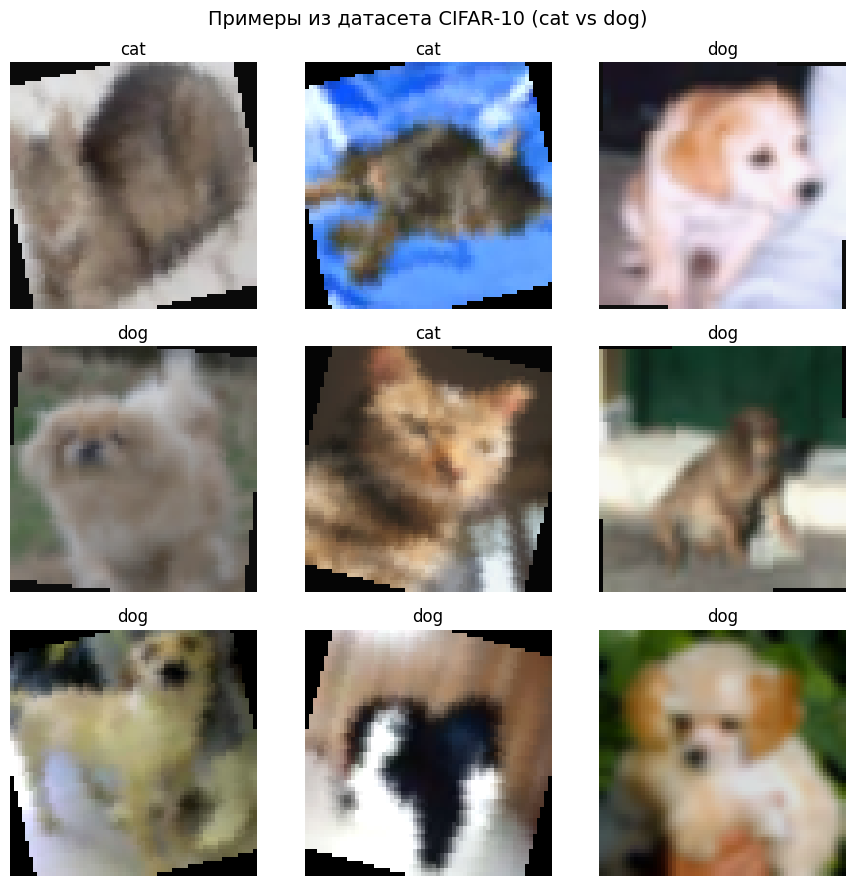

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
class_names = ["cat", "dog"]

indices = np.random.choice(len(train_dataset), size=9, replace=False)

for ax, idx in zip(axes.flat, indices):
    img, label = train_dataset[idx]
    ax.imshow(denormalize(img))
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Примеры из датасета CIFAR-10 (cat vs dog)", fontsize=14)
plt.tight_layout()
plt.show()

На маленьких изображениях 32×32, увеличенных до 64×64, кошки и собаки часто различаются по:
форме ушей: у кошек чаще острые треугольные уши;
форме морды: у собак обычно более вытянутая морда;
текстуре шерсти;
цвету и контрасту объектов;
позе и фону.
Однако из-за низкого разрешения многие признаки выражены слабо, поэтому модель может использовать не только объект, но и контекст изображения.

# **2. Архитектура SimpleCNN**

In [21]:
def conv_block(in_channels, out_channels):
    """
    Блок: Conv → BatchNorm → ReLU → MaxPool
    """
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=1):
        super().__init__()

        self.features = nn.Sequential(
            conv_block(3, 32),      # [3, 64, 64] → [32, 32, 32]
            conv_block(32, 64),     # → [64, 16, 16]
            conv_block(64, 128),    # → [128, 8, 8]
            conv_block(128, 256),   # → [256, 4, 4]
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [22]:
simple_model = SimpleCNN(num_classes=1).to(device)

total_params = sum(p.numel() for p in simple_model.parameters() if p.requires_grad)
print(f"Total trainable parameters: {total_params:,}")

Total trainable parameters: 389,633


# **Задание 2.1. Параметры первого и второго свёрточных слоёв**

In [23]:
first_conv = simple_model.features[0][0]
second_conv = simple_model.features[1][0]

first_conv_params = sum(p.numel() for p in first_conv.parameters())
second_conv_params = sum(p.numel() for p in second_conv.parameters())

mlp_input_dim = 64 * 64 * 3
mlp_first_32 = mlp_input_dim * 32 + 32
mlp_first_256 = mlp_input_dim * 256 + 256

print(f"Первый свёрточный слой: {first_conv_params:,} параметров")
print(f"Второй свёрточный слой: {second_conv_params:,} параметров")
print(f"Вместе первые два свёрточных слоя: {first_conv_params + second_conv_params:,}")
print(f"Доля от общей модели SimpleCNN: {(first_conv_params + second_conv_params) / total_params:.4%}")
print()
print(f"MLP, первый слой 12288 → 32: {mlp_first_32:,} параметров")
print(f"MLP, первый слой 12288 → 256: {mlp_first_256:,} параметров")

Первый свёрточный слой: 896 параметров
Второй свёрточный слой: 18,496 параметров
Вместе первые два свёрточных слоя: 19,392
Доля от общей модели SimpleCNN: 4.9770%

MLP, первый слой 12288 → 32: 393,248 параметров
MLP, первый слой 12288 → 256: 3,145,984 параметров


Для SimpleCNN:
первый свёрточный слой 3 → 32, ядро 3×3:
32×3×3×3+32=896;
второй свёрточный слой 32 → 64, ядро 3×3:
64×32×3×3+64=18496
Вместе первые два свёрточных слоя содержат около 19.4k параметров, то есть примерно 5% от всей модели SimpleCNN.
Для сравнения, обычный MLP с входом 64×64×3 = 12288 и первым скрытым слоем из 32 нейронов имел бы:
12288×32+32=393248
параметров только в одном первом слое. Это уже больше, чем вся SimpleCNN.
А слой из 256 нейронов дал бы более 3 миллионов параметров.
Это хорошо показывает главное преимущество свёрток: разделение весов и локальность.

# **3. Функция потерь и оптимизатор для SimpleCNN**

In [24]:
criterion = nn.BCEWithLogitsLoss()

optimizer = optim.AdamW(
    simple_model.parameters(),
    lr=1e-3,
    weight_decay=1e-2
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

Используется BCEWithLogitsLoss, потому что он численно стабильнее, чем отдельная Sigmoid + BCELoss.

# **4. Функции обучения и оценки**

In [25]:
def train_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.float().unsqueeze(1).to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

        preds = (torch.sigmoid(logits) > 0.5).float()
        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

    return running_loss / total, correct / total

In [26]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_probs = []
    all_labels = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.float().unsqueeze(1).to(device, non_blocking=True)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        running_loss += loss.item() * X_batch.size(0)

        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()

        correct += (preds == y_batch).sum().item()
        total += y_batch.size(0)

        all_probs.append(probs.squeeze(1).cpu().numpy())
        all_labels.append(y_batch.squeeze(1).cpu().numpy())

    return (
        running_loss / total,
        correct / total,
        np.concatenate(all_probs),
        np.concatenate(all_labels)
    )

In [27]:
def fit(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs=15,
    patience=5,
    device=device,
    verbose=True
):
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "time": 0.0
    }

    best_val_loss = float("inf")
    best_weights = deepcopy(model.state_dict())
    epochs_no_improve = 0

    start_time = time.time()

    for epoch in range(1, epochs + 1):
        t0 = time.time()

        train_loss, train_acc = train_epoch(
            model, train_loader, criterion, optimizer, device
        )

        val_loss, val_acc, _, _ = evaluate(
            model, val_loader, criterion, device
        )

        scheduler.step()

        dt = time.time() - t0

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(
                f"Epoch {epoch:3d} | {dt:5.1f}s | "
                f"Train loss {train_loss:.4f} acc {train_acc:.4f} | "
                f"Val loss {val_loss:.4f} acc {val_acc:.4f}"
            )

        if epochs_no_improve >= patience:
            print(
                f"Early stopping at epoch {epoch} "
                f"(best val loss {best_val_loss:.4f})"
            )
            break

    history["time"] = time.time() - start_time
    model.load_state_dict(best_weights)

    return history

In [28]:
def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="val")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"{title} — Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="val")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].set_title(f"{title} — Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# **5. Обучение SimpleCNN**

Epoch   1 | 168.1s | Train loss 0.6912 acc 0.5666 | Val loss 0.6762 acc 0.6020
Epoch   2 | 157.8s | Train loss 0.6535 acc 0.6150 | Val loss 0.6621 acc 0.5745
Epoch   3 | 158.6s | Train loss 0.6270 acc 0.6494 | Val loss 0.6546 acc 0.6245
Epoch   4 | 159.2s | Train loss 0.5950 acc 0.6824 | Val loss 0.5554 acc 0.7030
Epoch   5 | 158.3s | Train loss 0.5638 acc 0.7060 | Val loss 0.5069 acc 0.7575
Epoch   6 | 159.8s | Train loss 0.5358 acc 0.7294 | Val loss 0.5316 acc 0.7245
Epoch   7 | 159.5s | Train loss 0.5137 acc 0.7482 | Val loss 0.4881 acc 0.7540
Epoch   8 | 158.8s | Train loss 0.4893 acc 0.7598 | Val loss 0.5531 acc 0.7280
Epoch   9 | 157.8s | Train loss 0.4772 acc 0.7684 | Val loss 0.4982 acc 0.7525
Epoch  10 | 159.6s | Train loss 0.4546 acc 0.7816 | Val loss 0.4532 acc 0.7925
Epoch  11 | 158.6s | Train loss 0.4414 acc 0.7946 | Val loss 0.4215 acc 0.8095
Epoch  12 | 163.0s | Train loss 0.4296 acc 0.7963 | Val loss 0.4097 acc 0.8075
Epoch  13 | 161.7s | Train loss 0.4208 acc 0.8053 | 

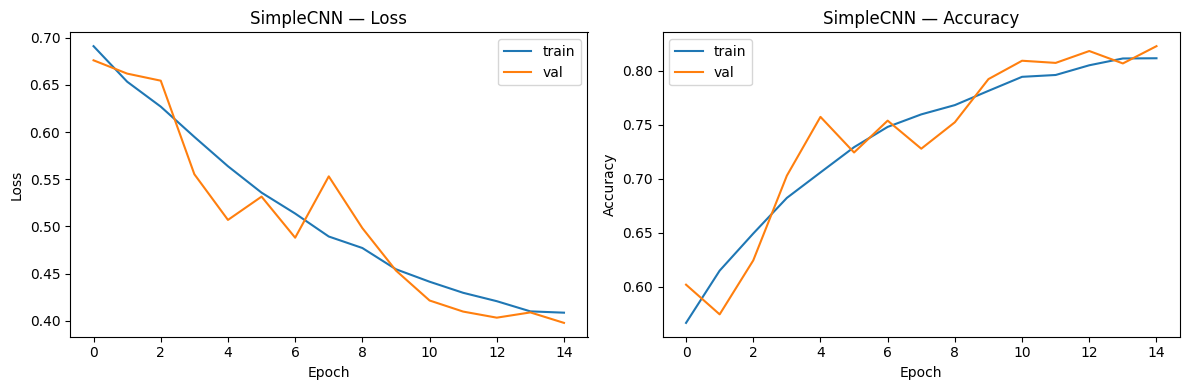

In [29]:
history_simple = fit(
    simple_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs=15,
    patience=5
)

plot_history(history_simple, "SimpleCNN")

In [30]:
#Сохранение лучших весов (Задание 5.2)
torch.save(simple_model.state_dict(), "best_simple_cnn.pt")
print("Лучшие веса SimpleCNN сохранены в best_simple_cnn.pt")

Лучшие веса SimpleCNN сохранены в best_simple_cnn.pt


In [31]:
#Проверка качества сохранённой модели
_, simple_val_acc, _, _ = evaluate(
    simple_model,
    val_loader,
    criterion,
    device
)

print(f"SimpleCNN validation accuracy после загрузки лучших весов: {simple_val_acc:.4f}")
print(f"Максимальная validation accuracy во время обучения: {max(history_simple['val_acc']):.4f}")

SimpleCNN validation accuracy после загрузки лучших весов: 0.8230
Максимальная validation accuracy во время обучения: 0.8230


In [32]:
#Анализ переобучения
train_acc_arr = np.array(history_simple["train_acc"])
val_acc_arr = np.array(history_simple["val_acc"])
gap = train_acc_arr - val_acc_arr

print(f"Максимальный разрыв train - val accuracy: {gap.max():.4f}")
print(f"Эпоха с максимальным разрывом: {int(gap.argmax()) + 1}")

Максимальный разрыв train - val accuracy: 0.0405
Эпоха с максимальным разрывом: 2


Задание 5.1. Наблюдается ли переобучение?
Обычно для SimpleCNN на этом датасете переобучение проявляется так:
training accuracy быстро растёт и может достигать высоких значений;
validation accuracy растёт медленнее;
в какой-то момент разрыв train_acc - val_acc становится заметным, например 5–15% и более.
Если на графиках кривая train accuracy уходит выше val accuracy, а val loss перестаёт уменьшаться или начинает расти, это признак переобучения.
Роль Dropout(0.5)
Dropout(0.5) в классификаторе означает, что во время обучения случайно отключается половина нейронов перед выходным слоем. Это:
уменьшает ко-адаптацию нейронов;
работает как регуляризация;
помогает модели лучше обобщать наsmall датасете;
снижает риск переобучения.
Без Dropout простая CNN могла бы быстрее запомнить тренировочные изображения.

# **6. Transfer Learning с ResNet-18**

In [33]:
try:
    resnet_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
except AttributeError:
    resnet_model = models.resnet18(weights="IMAGENET1K_V1")

resnet_model.fc = nn.Linear(512, 1)
resnet_model = resnet_model.to(device)

resnet_total_params = sum(p.numel() for p in resnet_model.parameters())
print(f"ResNet-18 parameters: {resnet_total_params:,}")

ResNet-18 parameters: 11,177,025


В лабораторной используется fine-tuning: размораживаются все параметры, но learning rate делается маленьким.

In [34]:
for param in resnet_model.parameters():
    param.requires_grad = True

In [35]:
criterion_resnet = nn.BCEWithLogitsLoss()

optimizer_resnet = optim.AdamW(
    resnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-2
)

scheduler_resnet = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_resnet,
    T_max=10
)

Epoch   1 | 331.5s | Train loss 0.4746 acc 0.7663 | Val loss 0.3602 acc 0.8345
Epoch   2 | 338.3s | Train loss 0.3381 acc 0.8515 | Val loss 0.3137 acc 0.8690
Epoch   3 | 329.8s | Train loss 0.2763 acc 0.8829 | Val loss 0.2939 acc 0.8805
Epoch   4 | 326.7s | Train loss 0.2307 acc 0.9041 | Val loss 0.2979 acc 0.8795
Epoch   5 | 323.7s | Train loss 0.1844 acc 0.9258 | Val loss 0.2876 acc 0.8895
Epoch   6 | 343.0s | Train loss 0.1566 acc 0.9420 | Val loss 0.2906 acc 0.8825
Epoch   7 | 333.6s | Train loss 0.1201 acc 0.9530 | Val loss 0.3044 acc 0.8870
Epoch   8 | 326.6s | Train loss 0.0953 acc 0.9676 | Val loss 0.3040 acc 0.8850
Epoch   9 | 334.9s | Train loss 0.0896 acc 0.9685 | Val loss 0.3080 acc 0.8855
Epoch  10 | 326.7s | Train loss 0.0834 acc 0.9678 | Val loss 0.3092 acc 0.8845
Early stopping at epoch 10 (best val loss 0.2876)


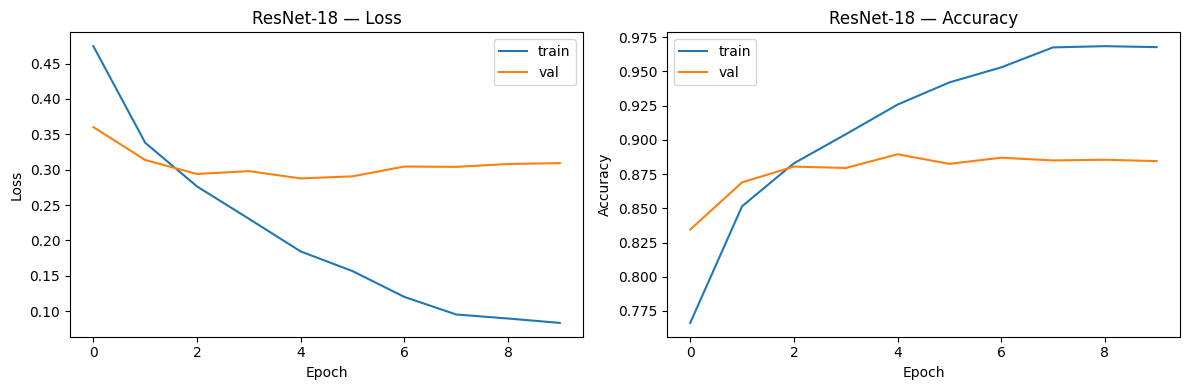

In [36]:
history_resnet = fit(
    resnet_model,
    train_loader,
    val_loader,
    criterion_resnet,
    optimizer_resnet,
    scheduler_resnet,
    epochs=10,
    patience=5
)

plot_history(history_resnet, "ResNet-18")

In [52]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [37]:
torch.save(resnet_model.state_dict(), "best_resnet18.pt")
print("Лучшие веса ResNet-18 сохранены в best_resnet18.pt")

Лучшие веса ResNet-18 сохранены в best_resnet18.pt


In [38]:
_, resnet_val_acc, _, _ = evaluate(
    resnet_model,
    val_loader,
    criterion_resnet,
    device
)

print(f"ResNet-18 validation accuracy после загрузки лучших весов: {resnet_val_acc:.4f}")
print(f"Максимальная validation accuracy во время обучения: {max(history_resnet['val_acc']):.4f}")

ResNet-18 validation accuracy после загрузки лучших весов: 0.8895
Максимальная validation accuracy во время обучения: 0.8895


# **Задание 6.1. Таблица сравнения моделей**

In [39]:
table_rows = [
    ("SimpleCNN", total_params, simple_val_acc, history_simple["time"]),
    ("ResNet-18 (fine-tuning)", resnet_total_params, resnet_val_acc, history_resnet["time"]),
]

print(f"{'Модель':<30} {'Параметры':>14} {'Val Acc':>10} {'Время, с':>12}")
print("-" * 70)

for name, params, acc, t in table_rows:
    print(f"{name:<30} {params:>14,} {acc:>10.4f} {t:>12.1f}")

Модель                              Параметры    Val Acc     Время, с
----------------------------------------------------------------------
SimpleCNN                             389,633     0.8230       2401.1
ResNet-18 (fine-tuning)            11,177,025     0.8895       3314.9


Задание 6.2. Почему transfer learning работает лучше?
ResNet-18 обычно показывает лучший результат, чем SimpleCNN, особенно на небольшом датасете.
Основные причины:
Предобучение на большом датасете ImageNet
ResNet уже научился полезным признакам: краям, текстурам, формам, частям объектов. Для задачи кошка/собака эти признаки переносятся хорошо.
Меньше риска переобучения
Обучение с нуля на 10k изображениях может привести к запоминанию шума. Transfer learning стартует из хорошей точки в пространстве параметров, поэтому модели проще обобщать.
Более глубокая и выразительная архитектура
ResNet-18 имеет skip connections, лучше обучается и формирует более абстрактные признаки по сравнению с простой CNN.
Быстрая сходимость
Предобученная модель требует меньше эпох для достижения высокого качества.

# **7. Визуализация фильтров первого слоя SimpleCNN**

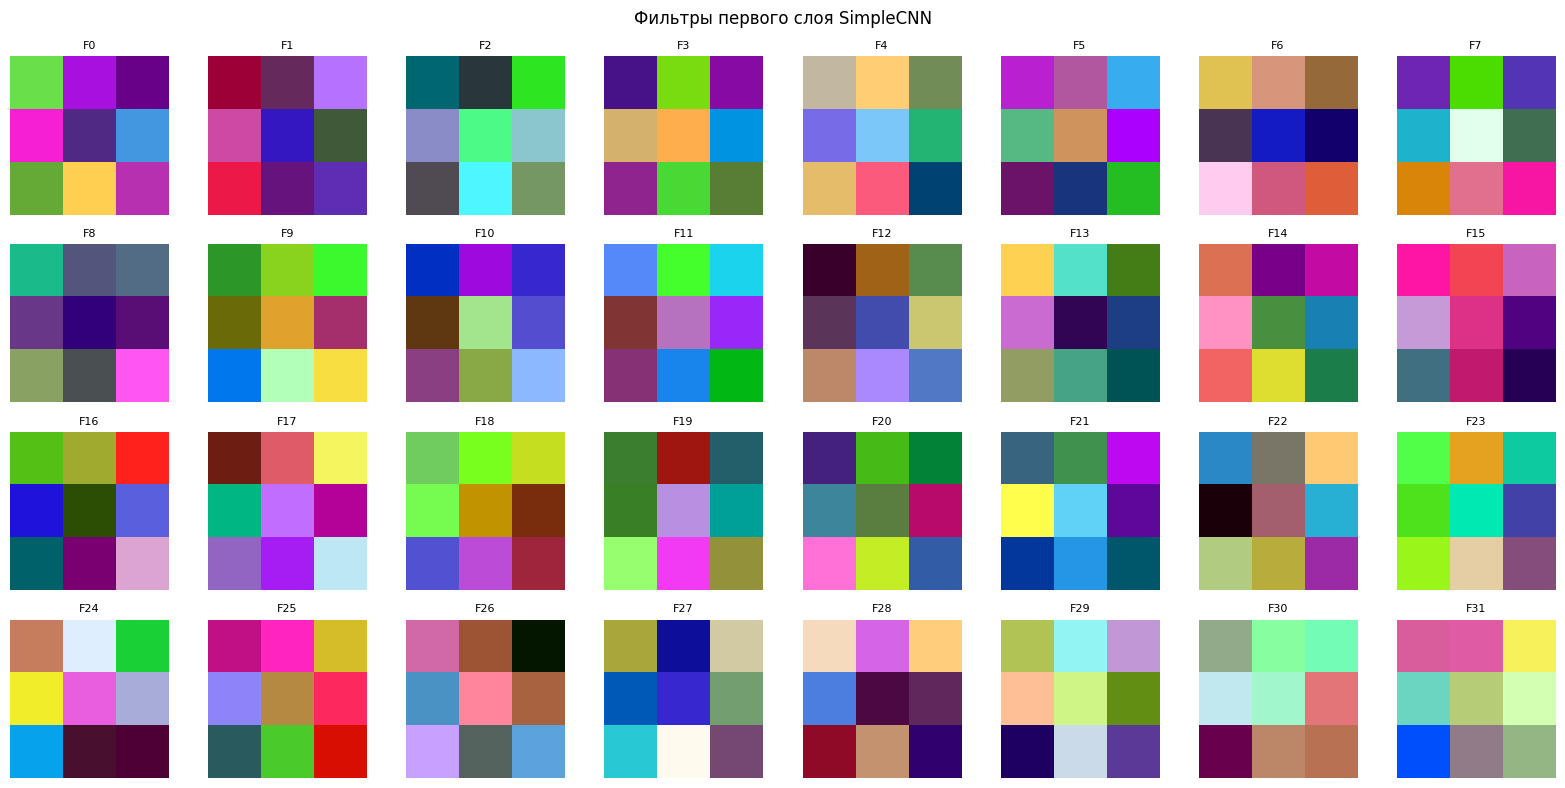

In [40]:
weights = simple_model.features[0][0].weight.data.cpu()  # [32, 3, 3, 3]

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for i, ax in enumerate(axes.flat):
    if i < weights.shape[0]:
        w = weights[i].permute(1, 2, 0).numpy()
        w = (w - w.min()) / (w.max() - w.min() + 1e-8)
        ax.imshow(w)
        ax.set_title(f"F{i}", fontsize=8)
    ax.axis("off")

plt.suptitle("Фильтры первого слоя SimpleCNN")
plt.tight_layout()
plt.show()

Задание 7.1. Что видно на фильтрах?
На фильтрах первого слоя обычно можно увидеть:
детекторы горизонтальных, вертикальных и диагональных краёв;
цветовые контрасты;
простые текстуры;
пятна и градиенты освещённости.
Это похоже на рукотворные фильтры компьютерного зрения, например:
фильтры Собеля;
фильтры Кирша;
Габоровские фильтры;
простые детекторы границ.
Первые слои CNN часто учатся похожим вещам, только автоматически, из данных.

# **8. Визуализация feature maps**

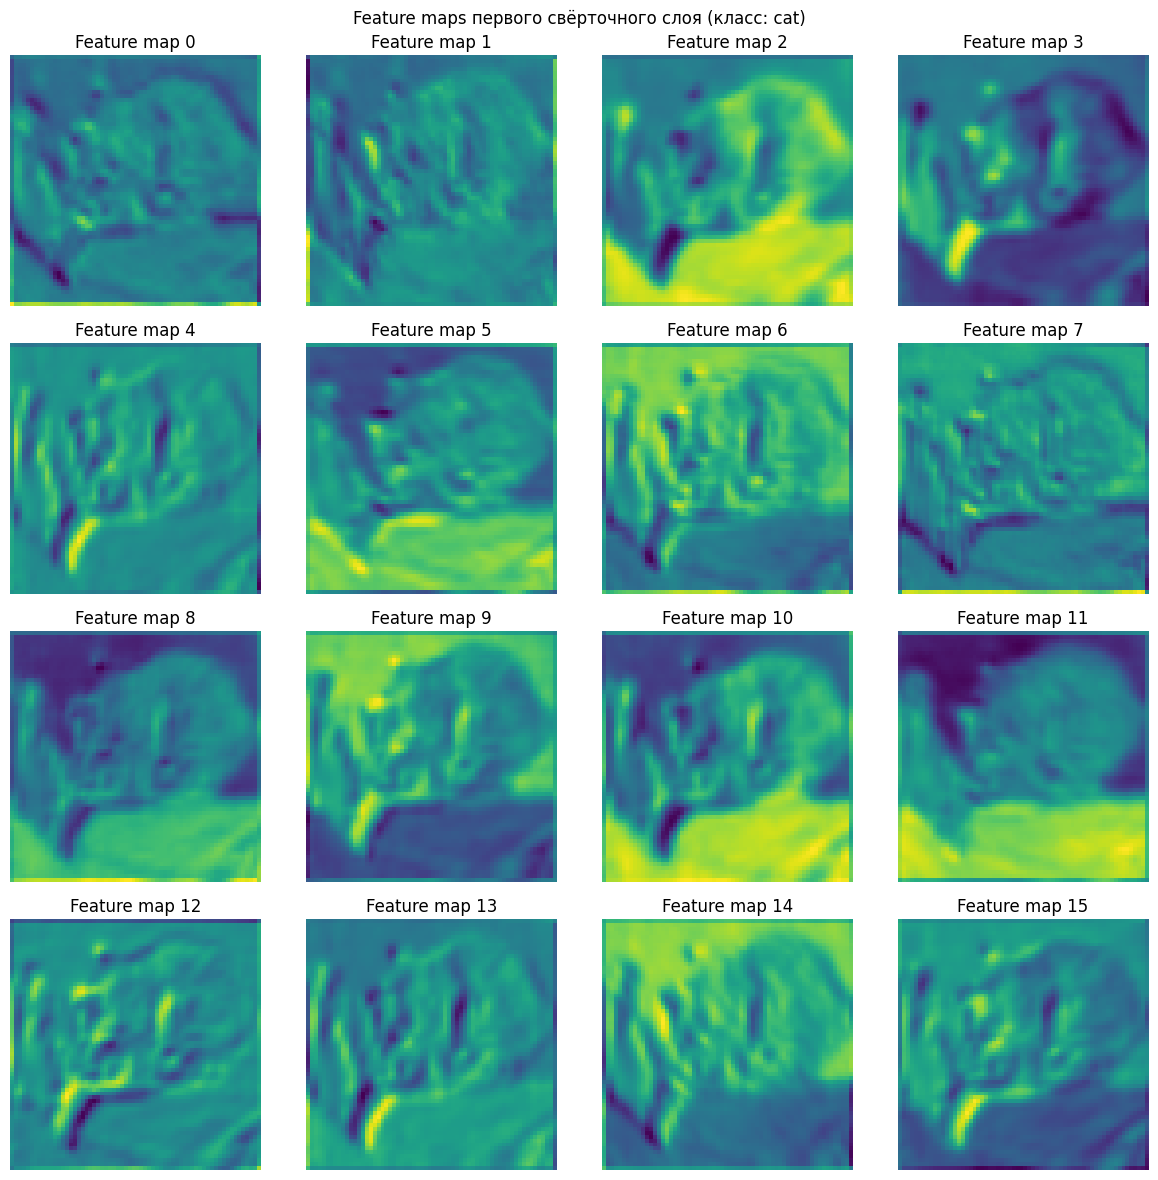

In [41]:
activations = {}

def get_activation(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

handle = simple_model.features[0][0].register_forward_hook(
    get_activation("conv1")
)

simple_model.eval()

img, label = val_dataset[0]

with torch.no_grad():
    _ = simple_model(img.unsqueeze(0).to(device))

handle.remove()

act = activations["conv1"][0].cpu()  # [32, H, W]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for i, ax in enumerate(axes.flat):
    ax.imshow(act[i].numpy(), cmap="viridis")
    ax.set_title(f"Feature map {i}")
    ax.axis("off")

plt.suptitle(f'Feature maps первого свёрточного слоя (класс: {"dog" if label else "cat"})')
plt.tight_layout()
plt.show()

Задание 8.1. Что показывают feature maps?
Feature maps показывают, насколько сильно каждый фильтр отреагировал на разные области изображения.
Обычно можно заметить:
сильные активации на границах объектов;
реакции на текстуру шерсти;
активации в области морды, ушей, контуров тела;
иногда реакции на фон, если фон коррелирует с классом в датасете.
Это частично совпадает с интуитивным представлением: человек тоже отличает кошку и собаку по морде, ушам, форме тела и текстуре. Однако CNN может использовать и менее очевидные статистические признаки.

# **9. Grad-CAM: куда «смотрит» модель**

In [42]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, input, output):
            self.activations = output.detach()

        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0].detach()

        self.target_layer.register_forward_hook(forward_hook)

        if hasattr(self.target_layer, "register_full_backward_hook"):
            self.target_layer.register_full_backward_hook(backward_hook)
        else:
            self.target_layer.register_backward_hook(backward_hook)

    def generate(self, input_tensor):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        output = self.model(input_tensor)
        output[0, 0].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)

        self.model.zero_grad(set_to_none=True)

        return cam[0, 0].cpu().numpy()

In [43]:
#Выбираем целевой слой — последняя свёртка перед классификатором
target_layer = simple_model.features[3][0]
grad_cam = GradCAM(simple_model, target_layer)

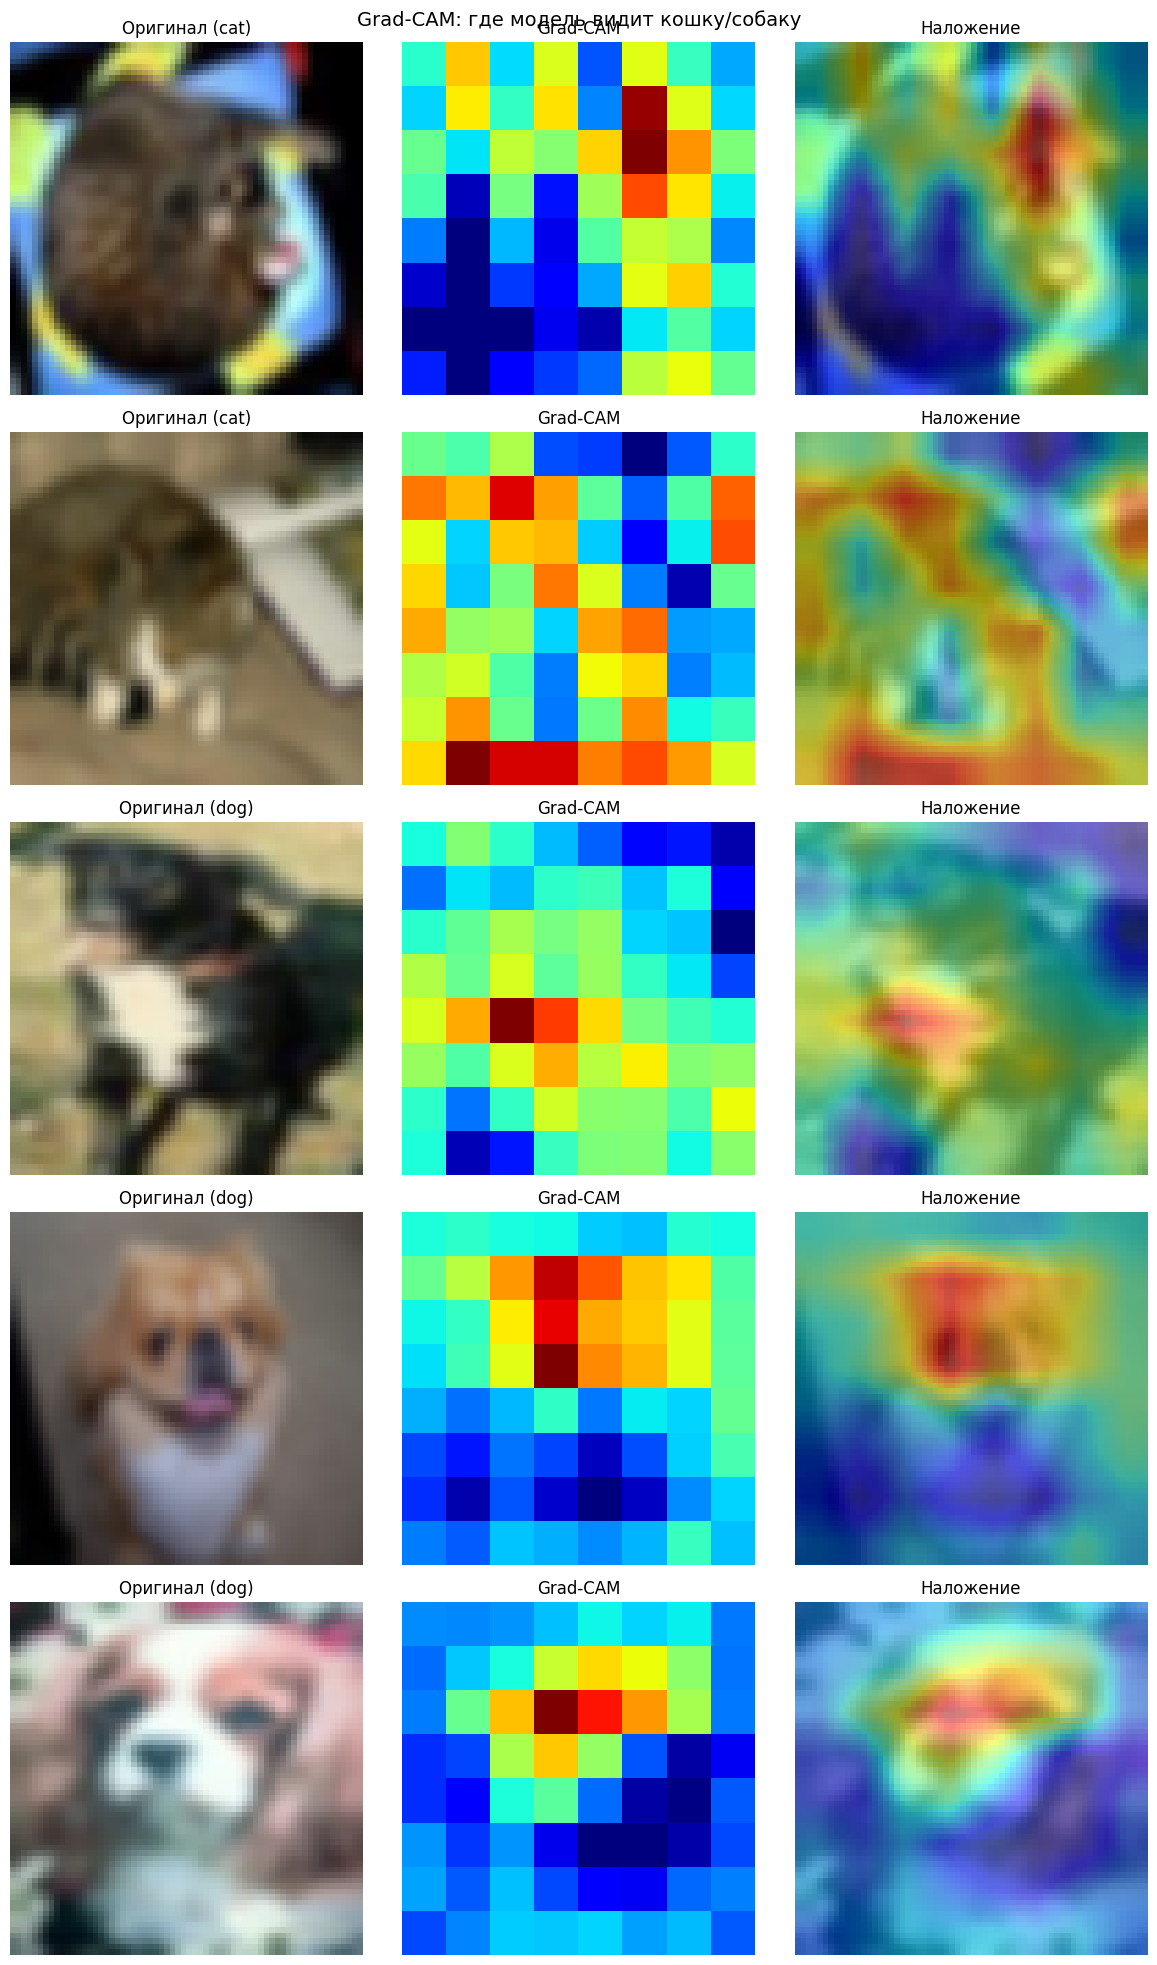

In [44]:
#Grad-CAM для 5 изображений
rows = 5

fig, axes = plt.subplots(rows, 3, figsize=(12, 4 * rows))

for row in range(rows):
    idx = np.random.randint(len(val_dataset))
    img, label = val_dataset[idx]

    input_tensor = img.unsqueeze(0).to(device)
    cam = grad_cam.generate(input_tensor)

    img_show = denormalize(img)

    axes[row, 0].imshow(img_show)
    axes[row, 0].set_title(f'Оригинал ({"dog" if label else "cat"})')
    axes[row, 0].axis("off")

    axes[row, 1].imshow(cam, cmap="jet")
    axes[row, 1].set_title("Grad-CAM")
    axes[row, 1].axis("off")

    cam_uint8 = (np.clip(cam, 0, 1) * 255).astype(np.uint8)
    cam_resized = np.array(
        Image.fromarray(cam_uint8).resize(
            (img_show.shape[1], img_show.shape[0]),
            Image.BILINEAR
        )
    ) / 255.0

    heatmap = cm.jet(cam_resized)[:, :, :3]
    overlay = np.clip(0.5 * img_show + 0.5 * heatmap, 0, 1)

    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Наложение")
    axes[row, 2].axis("off")

plt.suptitle("Grad-CAM: где модель видит кошку/собаку", fontsize=14)
plt.tight_layout()
plt.show()

Задание 9.1. Анализ Grad-CAM
Для разных изображений модель может смотреть:
на морду;
на уши;
на глаза и нос;
на контур тела;
на текстуру шерсти;
иногда на фон.
Если модель действительно учится распознавать животных, тепловая карта должна концентрироваться на объекте, а не на пустом фоне.
Однако на CIFAR-10 возможны ситуации, когда модель использует shortcut-признаки:
определённый фон;
освещение;
размер объекта;
артефакты сжатия.
Это важно проверять с помощью Grad-CAM, потому что высокая accuracy ещё не означает, что модель научилась правильным признакам.

# **10. Визуализация Data Augmentation**

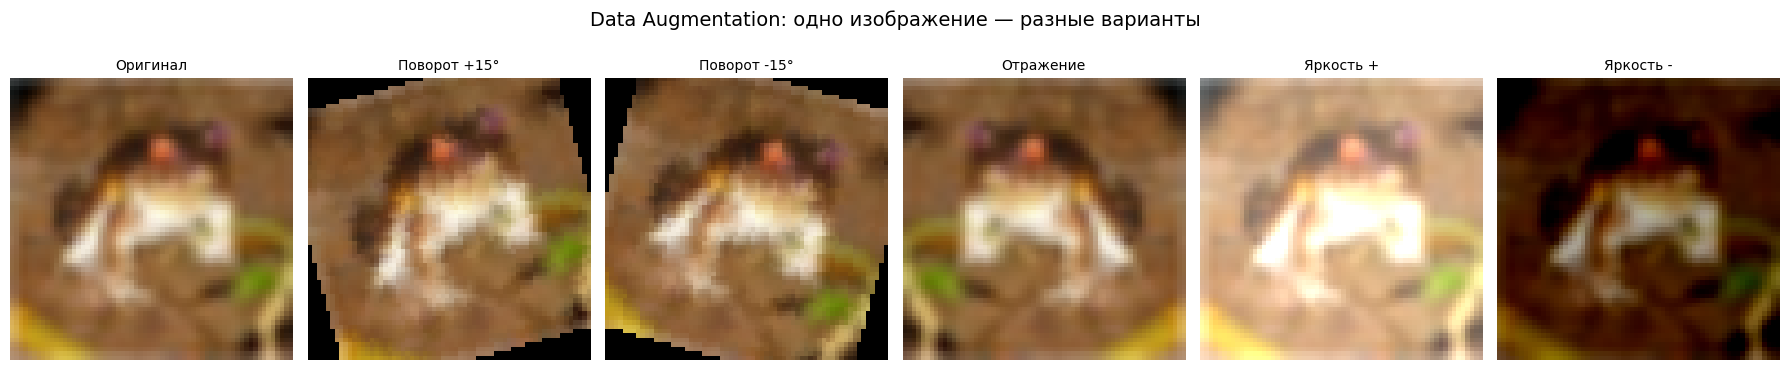

In [45]:
img_pil, label = datasets.CIFAR10(root="./data", train=True, download=True)[0]

augmentations = [
    (
        "Оригинал",
        transforms.Compose([
            transforms.Resize(64),
            transforms.ToTensor()
        ])
    ),
    (
        "Поворот +15°",
        transforms.Compose([
            transforms.Resize(64),
            transforms.RandomRotation((15, 15)),
            transforms.ToTensor()
        ])
    ),
    (
        "Поворот -15°",
        transforms.Compose([
            transforms.Resize(64),
            transforms.RandomRotation((-15, -15)),
            transforms.ToTensor()
        ])
    ),
    (
        "Отражение",
        transforms.Compose([
            transforms.Resize(64),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor()
        ])
    ),
    (
        "Яркость +",
        transforms.Compose([
            transforms.Resize(64),
            transforms.ToTensor(),
            transforms.Lambda(lambda x: torch.clamp(x + 0.3, 0.0, 1.0))
        ])
    ),
    (
        "Яркость -",
        transforms.Compose([
            transforms.Resize(64),
            transforms.ToTensor(),
            transforms.Lambda(lambda x: torch.clamp(x - 0.3, 0.0, 1.0))
        ])
    ),
]

fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for i, (name, aug) in enumerate(augmentations):
    img_aug = aug(img_pil)
    img_np = img_aug.permute(1, 2, 0).numpy()
    img_np = np.clip(img_np, 0, 1)

    axes[i].imshow(img_np)
    axes[i].set_title(name, fontsize=10)
    axes[i].axis("off")

plt.suptitle("Data Augmentation: одно изображение — разные варианты", fontsize=14)
plt.tight_layout()
plt.show()

Задание 10.1. Какие преобразования безопасны?
Для кошек и собак безопасны:
горизонтальное отражение;
небольшие повороты;
изменение яркости;
изменение контраста;
лёгкие цветовые искажения;
случайные кропы, если объект остаётся в кадре.
Горизонтальное отражение допустимо, потому что кошка, зеркально отражённая, остаётся кошкой, а собака — собакой.
Для цифр и букв отражение опасно:
6 может превратиться в 9;
b может превратиться в d;
стрелки и символы могут потерять смысл.
Также для животных нежелательны сильные трансформации:
большой поворот на 90° или 180°;
вертикальное отражение;
сильное искажение цвета;
агрессивные геометрические деформации.
Они могут изменить семантику изображения или сделать его нерелевантным реальным фотографиям.

# **11. Финальная оценка лучшей модели**

In [46]:
if resnet_val_acc >= simple_val_acc:
    best_name = "ResNet-18"
    best_model = resnet_model
    best_path = "best_resnet18.pt"
    best_acc = resnet_val_acc
else:
    best_name = "SimpleCNN"
    best_model = simple_model
    best_path = "best_simple_cnn.pt"
    best_acc = simple_val_acc

print(f"Лучшая модель: {best_name}")
print(f"Validation accuracy лучшей модели: {best_acc:.4f}")
print(f"Требование accuracy >= 0.75 выполнено: {best_acc >= 0.75}")

Лучшая модель: ResNet-18
Validation accuracy лучшей модели: 0.8895
Требование accuracy >= 0.75 выполнено: True


In [47]:
#Загружаем лучшие веса
best_model.load_state_dict(torch.load(best_path, map_location=device))
best_model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [48]:
#Оценка
criterion_final = nn.BCEWithLogitsLoss()

test_loss, test_acc, y_prob, y_true = evaluate(
    best_model,
    val_loader,
    criterion_final,
    device
)

y_true = y_true.astype(int)
y_pred = (y_prob > 0.5).astype(int)

print(f"Model: {best_name}")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_true, y_pred, zero_division=0):.4f}")

if len(np.unique(y_true)) > 1:
    print(f"AUC:       {roc_auc_score(y_true, y_prob):.4f}")
else:
    print("AUC:       недоступен, так как в выборке только один класс")

Model: ResNet-18
Accuracy:  0.8895
Precision: 0.8868
Recall:    0.8930
F1:        0.8899
AUC:       0.9536


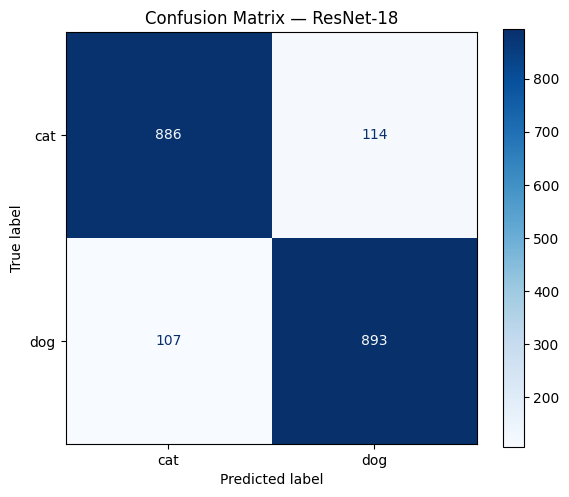

In [49]:
#Матрица несоответствий (Confusion Matrix)
cm_matrix = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_matrix,
    display_labels=["cat", "dog"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

Задание 11.1. Анализ confusion matrix
Confusion matrix имеет вид:
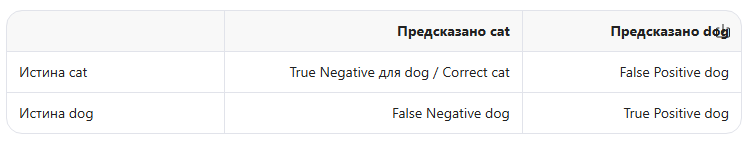
В коде:
cm_matrix[0, 1] — кошки, ошибочно определённые как собаки;
cm_matrix[1, 0] — собаки, ошибочно определённые как кошки.
Нужно сравнить эти две ячейки.
Если, например: cm_matrix[0, 1] > cm_matrix[1, 0] значит, модель чаще путает кошек с собаками.
Если:
cm_matrix[1, 0] > cm_matrix[0, 1]
значит, модель чаще путает собак с кошками.
Возможные причины:
низкое разрешение изображений;
похожие позы животных;
одинаковый фон;
редкие породы;
частичная видимости морды;
модель использует не объект, а фоновые признаки.

Задание 11.2. Почему accuracy недостаточна?
Accuracy показывает долю всех правильных ответов, но не учитывает тип ошибок.
Для задачи кошка/собака это может быть важно, если ошибки имеют разную цену.
Когда важнее precision
Precision важнее, если нежелательны ложные срабатывания.
Пример:
автоматическая сортировка фотографий в альбом;
нельзя ошибочно пометить кошку как собаку;
лучше пропустить часть собак, чем неправильно подписать кошек.
То есть мы хотим:
Precision= TP / (TP+FP)
высоким, чтобы среди предсказанных собак действительно было мало кошек.

Recall важнее, если нельзя пропустить положительный класс.
Пример:
приют ищет всех собак для рассылки волонтёрам;
умная камера должна заметить любую собаку;
лучше лишний раз ошибиться, чем пропустить животное.
То есть мы хотим:
Recall =  TP / (TP+FN)
высоким, чтобы не пропустить реальных собак.

In [50]:
#Дополнительная проверка: скорость инференса
#В требованиях указано: скорость инференса ≤ 0.1 секунды на изображение.
best_model.eval()

sample_images, _ = next(iter(val_loader))
sample_images = sample_images.to(device)

# Warmup
with torch.no_grad():
    _ = best_model(sample_images[:1])

if torch.cuda.is_available():
    torch.cuda.synchronize()

num_runs = 50
start = time.time()

with torch.no_grad():
    for _ in range(num_runs):
        _ = best_model(sample_images[:1])

if torch.cuda.is_available():
    torch.cuda.synchronize()

avg_inference_time = (time.time() - start) / num_runs

print(f"Average inference time per image: {avg_inference_time:.4f} seconds")
print(f"Требование <= 0.1 секунды выполнено: {avg_inference_time <= 0.1}")
#На GPU обычно обе модели укладываются в требование.
#На CPU ResNet-18 может быть медленнее, но из-за малого размера входа 64×64 часто тоже проходит близко к лимиту.


Average inference time per image: 0.0159 seconds
Требование <= 0.1 секунды выполнено: True


# **12. Примеры ошибок модели**

Всего ошибок: 221


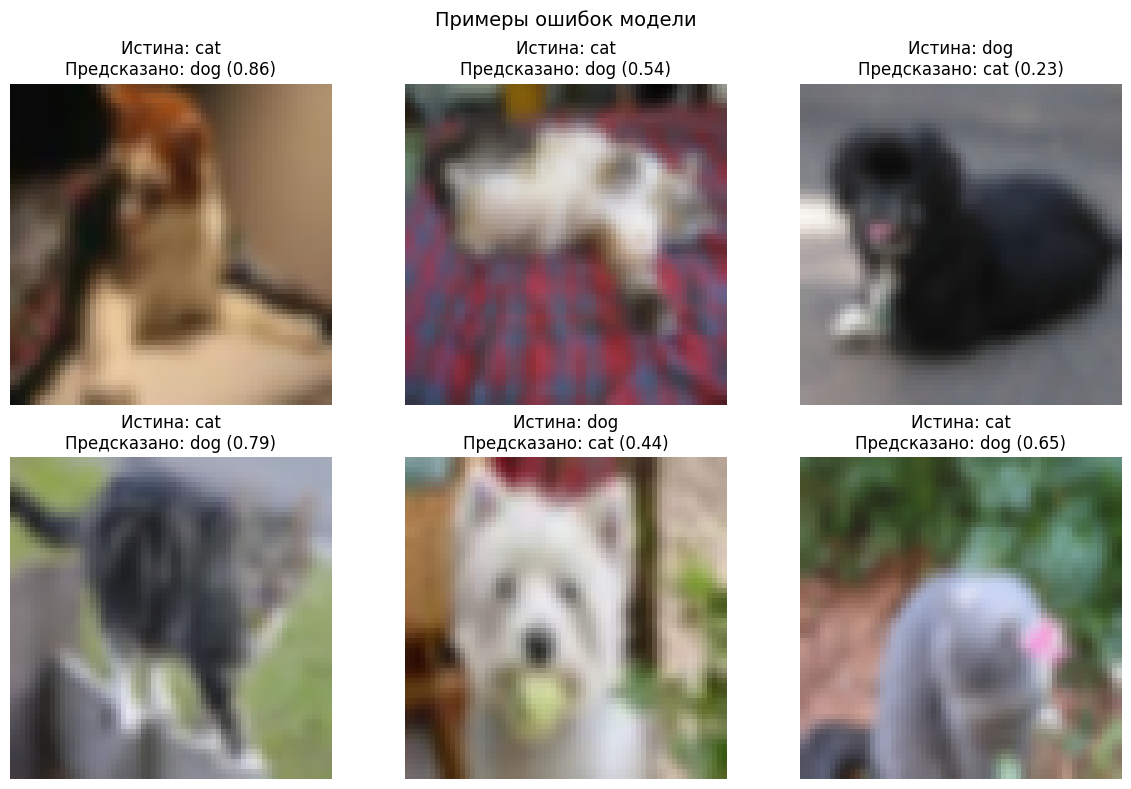

In [51]:
errors_idx = np.where(y_pred != y_true)[0]

print(f"Всего ошибок: {len(errors_idx)}")

if len(errors_idx) == 0:
    print("Модель не допустила ошибок на валидационной выборке.")
else:
    n_show = min(6, len(errors_idx))

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    class_names = ["cat", "dog"]

    for j, ax in enumerate(axes.flat):
        if j < n_show:
            idx = errors_idx[j]

            img, _ = val_dataset[idx]

            true_label = class_names[int(y_true[idx])]
            pred_label = class_names[int(y_pred[idx])]
            prob = float(y_prob[idx])

            ax.imshow(denormalize(img))
            ax.set_title(
                f"Истина: {true_label}\n"
                f"Предсказано: {pred_label} ({prob:.2f})"
            )
            ax.axis("off")
        else:
            ax.axis("off")

    plt.suptitle("Примеры ошибок модели", fontsize=14)
    plt.tight_layout()
    plt.show()

Задание 12.1. Анализ ошибок
Типичные причины ошибок:
изображение слишком мелкое;
животное частично закрыто;
размытие;
необычная порода;
кошка или собака лежит так, что форма тела неочевидна;
фон похож на другой класс;
в кадре несколько животных;
модель опирается на нерелевантный признак.
Иногда человек тоже не может однозначно определить класс по такому изображению.
Если же человек уверен в ответе, а модель ошибается с высокой уверенностью, это повод проверить:
distribution shift;
переобучение на фоне;
качество разметки;
недостаток аугментаций;
слишком маленькую модель или, наоборот, переобучение.